# EDA: AgERA5 daily series and cross-checks

Presents the outputs of `pipelines/02b_eda_agera5.py`. AgERA5 is derived from ERA5 reanalysis; agreement with ERA5-Land is a consistency check, not an independent validation.

In [1]:
from frostwatch_ml.evaluation import notebook as nb
from frostwatch_ml.evaluation import plots

## Coverage, NaN, cloud range and grid offset

In [2]:
nb.csv("data/processed/eda_agera5/coverage.csv").T

point_id,el_alto,oruro,patacamaya,calamarca,caracollo,corocoro,charana,huanuni
first_date,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31,1984-12-31
last_date,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25,2026-10-25
days,15274,15274,15274,15274,15274,15274,15274,15274
expected_days,15274,15274,15274,15274,15274,15274,15274,15274
non_daily_steps,0,0,0,0,0,0,0,0
duplicates,0,0,0,0,0,0,0,0
nan_cloud_cover_24h,0,0,0,0,0,0,0,0
nan_tmin_night_k,0,0,0,0,0,0,0,0
nan_rh_15h,0,0,0,0,0,0,0,0
cloud_below_0,0,0,0,0,0,0,0,0


## Cloud cover seasonal cycle

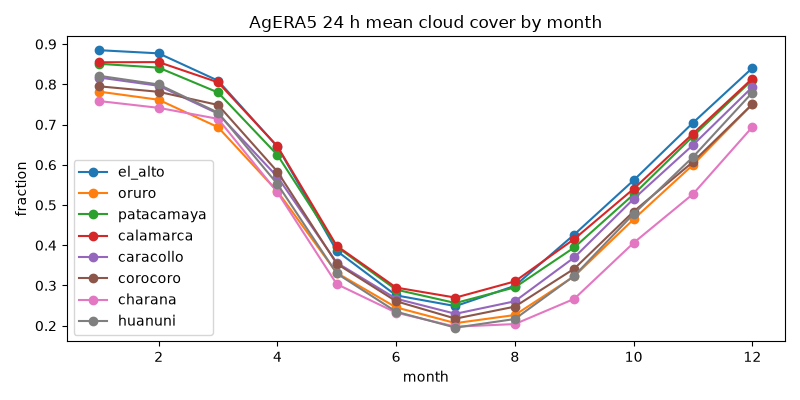

In [3]:
nb.figure(plots.lines(nb.csv("data/processed/eda_agera5/cloud_cover_by_month.csv"), "AgERA5 24 h mean cloud cover by month", "fraction"))

## Cross-checks against ERA5-Land

The night-time minimum dated D covers the night ending on the morning of D; the two correlation columns compare both alignments.

In [4]:
nb.csv("data/processed/eda_agera5/crosschecks.csv").round(3)

,n_days,tmin_corr_night_ending,tmin_corr_night_starting,tmin_bias_c,tmin_mae_c,frost_flag_agreement,frost_rate_agera5,frost_rate_era5land,rh_corr,rh_bias_pct,rh_mae_pct
point_id,,,,,,,,,,,
el_alto,14974,0.903,0.805,-0.560,0.982,0.900,0.224,0.177,0.883,-8.234,10.550
oruro,14974,0.939,0.846,0.095,0.844,0.907,0.221,0.199,0.962,-2.195,5.325
patacamaya,14974,0.923,0.814,0.016,0.956,0.907,0.336,0.337,0.932,5.017,7.055
calamarca,14974,0.941,0.820,-0.309,0.931,0.917,0.376,0.352,0.915,4.141,7.285
caracollo,14974,0.928,0.823,-0.207,0.983,0.921,0.206,0.215,0.956,-4.692,7.189
corocoro,14974,0.953,0.830,1.202,1.730,0.880,0.395,0.491,0.965,3.390,5.249
charana,14974,0.915,0.785,1.351,1.805,0.873,0.549,0.627,0.957,1.368,5.625
huanuni,14974,0.913,0.808,-0.624,1.009,0.889,0.420,0.361,0.964,1.717,5.835


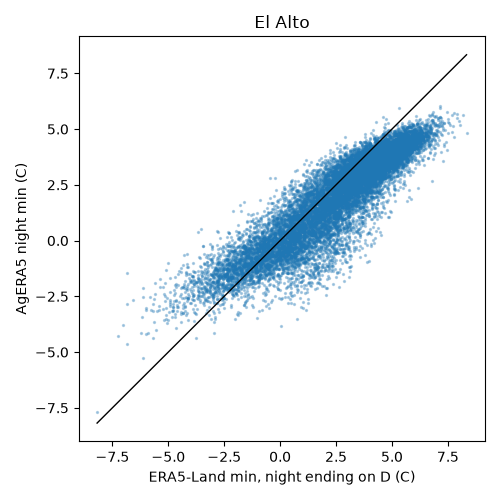

In [5]:
d = nb.parquet("data/processed/eda_agera5/daily_crosscheck.parquet")
el = d[d["point_id"] == "el_alto"].dropna()
nb.figure(plots.scatter(el["era5land_min_night_ending_c"], el["agera5_tmin_c"], "ERA5-Land min, night ending on D (C)", "AgERA5 night min (C)", "El Alto"))

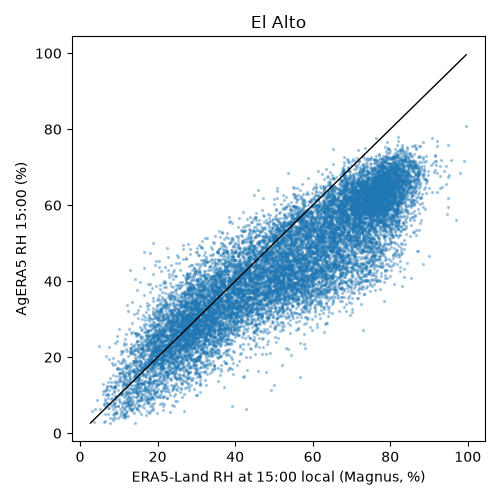

In [6]:
nb.figure(plots.scatter(el["era5land_rh_19utc"], el["agera5_rh15"], "ERA5-Land RH at 15:00 local (Magnus, %)", "AgERA5 RH 15:00 (%)", "El Alto"))